# SET 4

## __NOTE:__  _Update this with fhe filenames and folder path_

In [1]:
import pandas as pd

# Files names in order (V1, V2, etc)
filenames = [
    "metrics_log_power_1791203547.csv",
    "metrics_log_power_1791204245.csv",
    "metrics_log_power_1791206419.csv",
    "metrics_log_power_1791206981.csv",
    "metrics_log_power_1791212493.csv",
    "metrics_log_power_1791213029.csv",
]

# file path for the folder where the files are stored:
file_path = "../Metrics/MQ3_logs_10-05-2026/"

### &rarr; __CHECKING DATA:__

In [2]:
# STORING DATA FRAMES
dfs = {}
for i, filename in enumerate(filenames, start=1):
    full_path = file_path + filename
    dfs[f"v{i}"] = pd.read_csv(full_path)

In [3]:
dfs["v1"]

,id_line,Timestamp,Elapsed (s),Level (%),Voltage (mV),Temp (C),Charge Counter (uAh),Calculated Current (mA),Calculated Power (mW),Accumulated Power (mWh),...,Foreground App,Media App,Video Title,Title Source,Playback State,Video Clock,Video Session,Video Position (s),Video Position (mm:ss),Position Source
0,1,2026-10-05 07:32:27,0.25,48,3613,43.0,2517084,3285.86,11871.81,3.067,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Stopped,Idle,0,0.0,00:00,auto
1,2,2026-10-05 07:32:28,1.18,48,3613,43.0,2517084,3285.86,11871.81,6.332,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Stopped,Idle,0,0.0,00:00,auto
2,3,2026-10-05 07:32:29,2.17,48,3662,43.0,2517084,3285.86,12032.82,9.841,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Stopped,Idle,0,0.0,00:00,auto
3,4,2026-10-05 07:32:30,3.22,48,3662,43.0,2517084,3285.86,12032.82,13.852,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Stopped,Idle,0,0.0,00:00,auto
4,5,2026-10-05 07:32:31,4.42,48,3662,43.0,2517084,3285.86,12032.82,16.961,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Stopped,Idle,0,0.0,00:00,auto
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
429,430,2026-10-05 07:39:39,431.90,42,3539,46.0,2204406,0.00,0.00,1140.069,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Stopped,Stopped,0,0.0,00:00,auto
430,431,2026-10-05 07:39:40,432.91,42,3651,46.0,2204406,0.00,0.00,1140.069,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Stopped,Stopped,0,0.0,00:00,auto
431,432,2026-10-05 07:39:41,433.87,42,3651,46.0,2204406,0.00,0.00,1140.069,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Stopped,Stopped,0,0.0,00:00,auto
432,433,2026-10-05 07:39:42,435.20,42,3651,46.0,2204406,0.00,0.00,1140.069,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Stopped,Stopped,0,0.0,00:00,auto


In [4]:
# CHECKING MANUAL CONTROL RESULTS:
for i, filename in enumerate(filenames, start=1):
    df = dfs[f"v{i}"]
    total_seconds = (df["Video Session"] == 1).sum()
    minutes = total_seconds // 60
    seconds = total_seconds % 60

    print(f"v{i} Total time: {minutes}:{seconds:02d}")

v1 Total time: 6:15
v2 Total time: 4:55
v3 Total time: 6:13
v4 Total time: 3:41
v5 Total time: 6:13
v6 Total time: 4:34


### TABLES IN __DFS{}__ DICTIONARY:

In [5]:
# CHECKING MANUAL CONTROL RESULTS:
for i, filename in enumerate(filenames, start=1):
    df = dfs[f"v{i}"]
    total_seconds = (df["Video Session"] == 1).sum()
    minutes = total_seconds // 60
    seconds = total_seconds % 60

    print(f"v{i} Total time: {minutes}:{seconds:02d}")

v1 Total time: 6:15
v2 Total time: 4:55
v3 Total time: 6:13
v4 Total time: 3:41
v5 Total time: 6:13
v6 Total time: 4:34


### &rarr; __PLOTTING RESULTS:__

In [6]:
import matplotlib.pyplot as plt

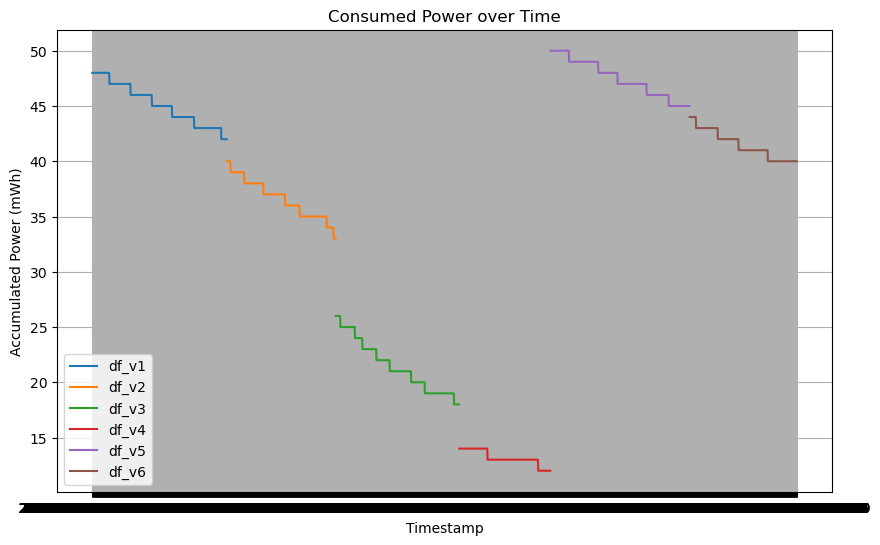

In [7]:
plt.figure(figsize=(10, 6))

for key, df in dfs.items():
    df.columns = df.columns.str.strip()
    plt.plot(df["Timestamp"], df["Level (%)"], label=f"df_{key}")

# Add titles, labels, and legend
plt.title("Consumed Power over Time")
plt.xlabel("Timestamp")
plt.ylabel("Accumulated Power (mWh)")
plt.legend()
plt.grid(True)

plt.show()

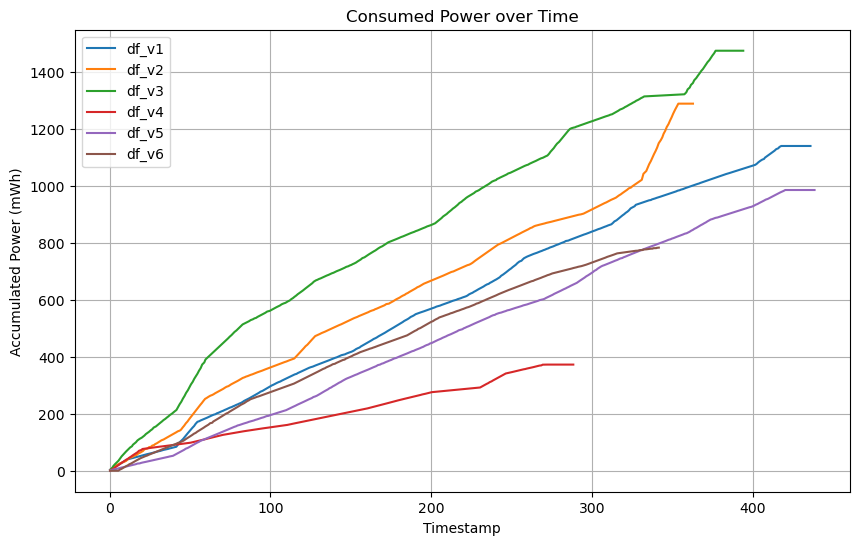

In [8]:
plt.figure(figsize=(10, 6))

for key, df in dfs.items():
    df.columns = df.columns.str.strip()
    plt.plot(df["Elapsed (s)"], df["Accumulated Power (mWh)"], label=f"df_{key}")

# Add titles, labels, and legend
plt.title("Consumed Power over Time")
plt.xlabel("Timestamp")
plt.ylabel("Accumulated Power (mWh)")
plt.legend()
plt.grid(True)

plt.show()

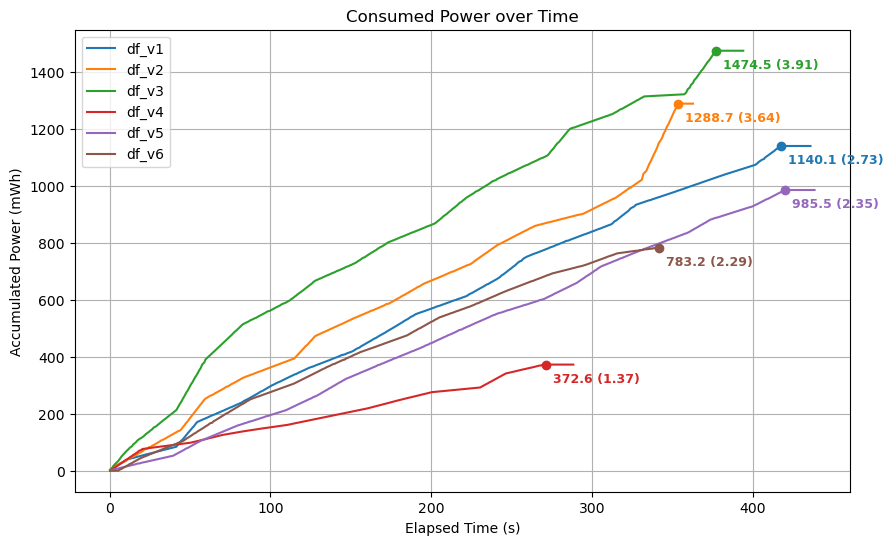

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for key, df in dfs.items():
    df.columns = df.columns.str.strip()
    x = df["Elapsed (s)"]
    y = df["Accumulated Power (mWh)"]
    
    # Plot the line and capture the line object to get its color
    line, = plt.plot(x, y, label=f"df_{key}")
    
    # Find the index and coordinates of the highest y-value
    max_idx = y.idxmax()
    max_x = x.loc[max_idx]
    max_y = y.loc[max_idx]
    
    # Calculate max value / max elapsed time
    ratio = max_y / max_x if max_x != 0 else 0
    
    # Add a matching dot at the highest point
    plt.scatter(max_x, max_y, color=line.get_color(), zorder=5)
    
    # Annotate with the value and ratio on the same line
    plt.annotate(
        f"{max_y:.1f} ({ratio:.2f})", 
        (max_x, max_y),
        textcoords="offset points",
        xytext=(5, -10),      # 10 points to the right, 8 points up
        ha='left',           # Aligned to the left so text extends to the right
        va='center',         # Vertically centered relative to the dot
        color=line.get_color(), 
        fontsize=9, 
        weight='bold'
    )

# Add titles, labels, and legend
plt.title("Consumed Power over Time")
plt.xlabel("Elapsed Time (s)")
plt.ylabel("Accumulated Power (mWh)")
plt.legend()
plt.grid(True)

plt.show()

### &rarr; __Real Conditions (vs Target)__:

In [10]:
summary_list = []

for key, df in dfs.items():
    summary_list.append({
        "DataFrame": f"{key}",  # Using key (or i if you have an index counter)
        "Initial Battery Level": df["Level (%)"].max(),
        "Avg Volume (%)": df["Volume (%)"].mean(),
        "Avg Brightness (%)": df["Brightness (%)"].mean(),
    })

# Create a final summary DataFrame
summary_df = pd.DataFrame(summary_list)
print(summary_df)

  DataFrame  Initial Battery Level  Avg Volume (%)  Avg Brightness (%)
0        v1                     48       19.505991               100.0
1        v2                     40       13.300000               100.0
2        v3                     26       13.300000               100.0
3        v4                     14       26.700000               100.0
4        v5                     50       20.000000               100.0
5        v6                     44       20.000000               100.0
